## 17 Environmental-Condition Travel Behavior (Flag 17)

### Dataset Overview
A constructed WorldTrace case with 700 trajectories. Geometry source: Observed map-matched NYC WorldTrace road paths or continuous road-aligned return traversals. Environmental, temporal, mode, vehicle, and event attributes are arranged to make all stated comparisons measurable without changing the route coordinates used by the figures.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Investigate changes in travel behavior and movement conditions under varying environmental conditions.

Role: Urban mobility analyst


Category: Distance-conditioned weather speed gaps, turn reductions, and spatial extent

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

Load the libraries used below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

Load the primary and supporting point tables.

In [ ]:
dataset_path='trajectories.csv'
df=pd.read_csv(dataset_path,low_memory=False)
df['departure_time']=pd.to_datetime(df.departure_time)
df['arrival_time']=pd.to_datetime(df.arrival_time)

In [ ]:
user_dataset_path='trajectory_points.csv'
user_df=pd.read_csv(user_dataset_path,low_memory=False)

### **Question 1**: Does the rainy-versus-dry car-speed difference become larger on longer routes?

#### Analysis action

Compare the same source-route families in rainy and dry weather, then relate each route family's speed gap to its distance.

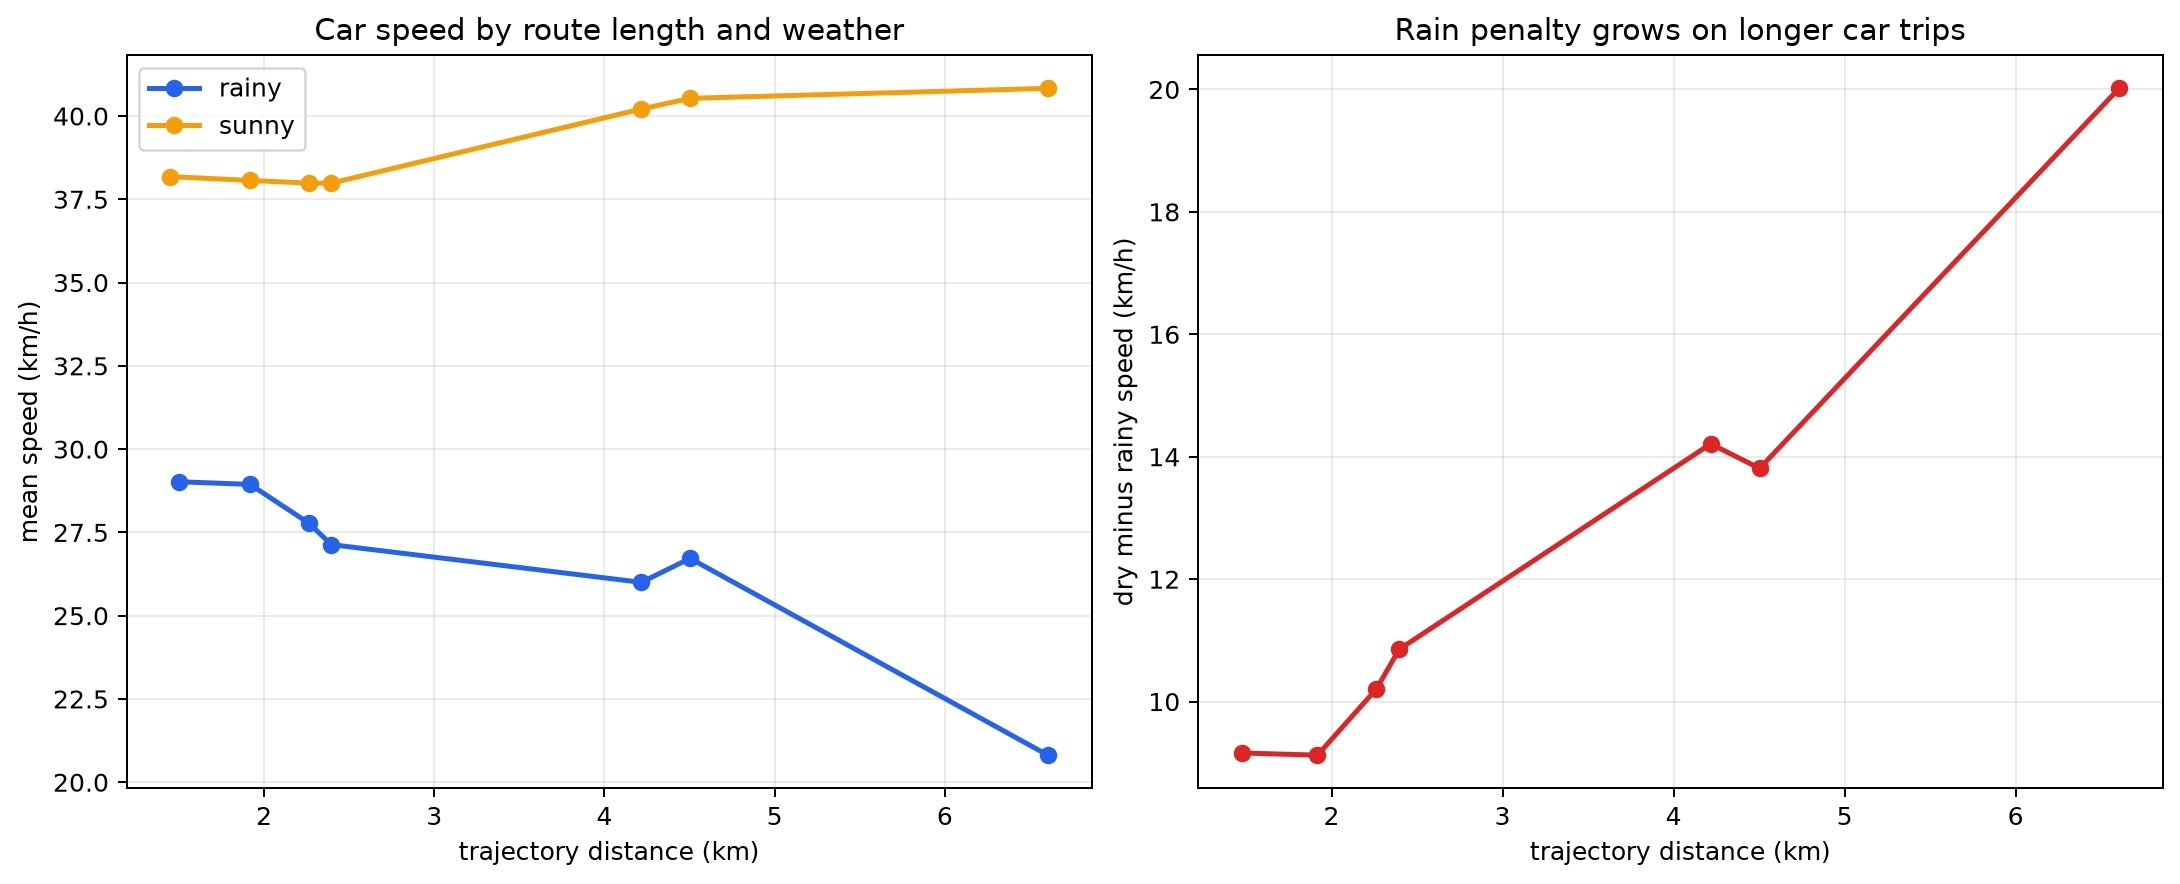

In [ ]:
c=df[df.travel_mode.eq('car')].copy()
route=(c.groupby(['source_trajectory_id','weather']).agg(distance_km=('trajectory_distance_km','mean'),speed_kmh=('mean_speed_kmh','mean')).reset_index())
pivot=route.pivot(index='source_trajectory_id',columns='weather',values='speed_kmh');pivot['distance_km']=route.groupby('source_trajectory_id').distance_km.mean();pivot['dry_minus_rainy_kmh']=pivot.sunny-pivot.rainy;pivot=pivot.sort_values('distance_km')
print('Overall car speed by weather');print(c.groupby('weather').mean_speed_kmh.agg(['mean','std','count']).round(2));print('Matched-route speed gaps');print(pivot.round(2));print('distance-gap correlation',round(pivot.distance_km.corr(pivot.dry_minus_rainy_kmh),3))
fig,ax=plt.subplots(1,2,figsize=(12,4.8),constrained_layout=True)
for weather,color in [('rainy','#2563eb'),('sunny','#f59e0b')]:
    q=route[route.weather.eq(weather)].sort_values('distance_km');ax[0].plot(q.distance_km,q.speed_kmh,marker='o',linewidth=2,label=weather,color=color)
ax[0].set(title='Car speed by route length and weather',xlabel='trajectory distance (km)',ylabel='mean speed (km/h)');ax[0].legend();ax[0].grid(alpha=.25)
ax[1].plot(pivot.distance_km,pivot.dry_minus_rainy_kmh,marker='o',linewidth=2,color='#dc2626');ax[1].set(title='Rain penalty grows on longer car trips',xlabel='trajectory distance (km)',ylabel='dry minus rainy speed (km/h)');ax[1].grid(alpha=.25)
plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex17_insight_1",
  "insight": "Rainy trajectories exhibit lower average speeds than dry-weather trajectories, but the reduction is substantially stronger for longer car trips than for short car trips.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Environmental-Condition Travel Behavior: Insight 1",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Does the rainy-versus-dry car-speed difference become larger on longer routes?",
  "actionable_insight": "Compare the same source-route families in rainy and dry weather, then relate each route family's speed gap to its distance.",
  "code": "c=df[df.travel_mode.eq('car')].copy()\nroute=(c.groupby(['source_trajectory_id','weather']).agg(distance_km=('trajectory_distance_km','mean'),speed_kmh=('mean_speed_kmh','mean')).reset_index())\npivot=route.pivot(index='source_trajectory_id',columns='weather',values='speed_kmh');pivot['distance_km']=route.groupby('source_trajectory_id').distance_km.mean();pivot['dry_minus_rainy_kmh']=pivot.sunny-pivot.rainy;pivot=pivot.sort_values('distance_km')\nprint('Overall car speed by weather');print(c.groupby('weather').mean_speed_kmh.agg(['mean','std','count']).round(2));print('Matched-route speed gaps');print(pivot.round(2));print('distance-gap correlation',round(pivot.distance_km.corr(pivot.dry_minus_rainy_kmh),3))\nfig,ax=plt.subplots(1,2,figsize=(12,4.8),constrained_layout=True)\nfor weather,color in [('rainy','#2563eb'),('sunny','#f59e0b')]:\n    q=route[route.weather.eq(weather)].sort_values('distance_km');ax[0].plot(q.distance_km,q.speed_kmh,marker='o',linewidth=2,label=weather,color=color)\nax[0].set(title='Car speed by route length and weather',xlabel='trajectory distance (km)',ylabel='mean speed (km/h)');ax[0].legend();ax[0].grid(alpha=.25)\nax[1].plot(pivot.distance_km,pivot.dry_minus_rainy_kmh,marker='o',linewidth=2,color='#dc2626');ax[1].set(title='Rain penalty grows on longer car trips',xlabel='trajectory distance (km)',ylabel='dry minus rainy speed (km/h)');ax[1].grid(alpha=.25)\nplt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "weather",
    "matched_road_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: How does the local speed reduction at frequent turns vary between rainy and mild weather across temperatures?

#### Analysis action

Derive each trajectory's ordinary-section minus high-turn-section speed from point observations, then aggregate by weather and temperature.

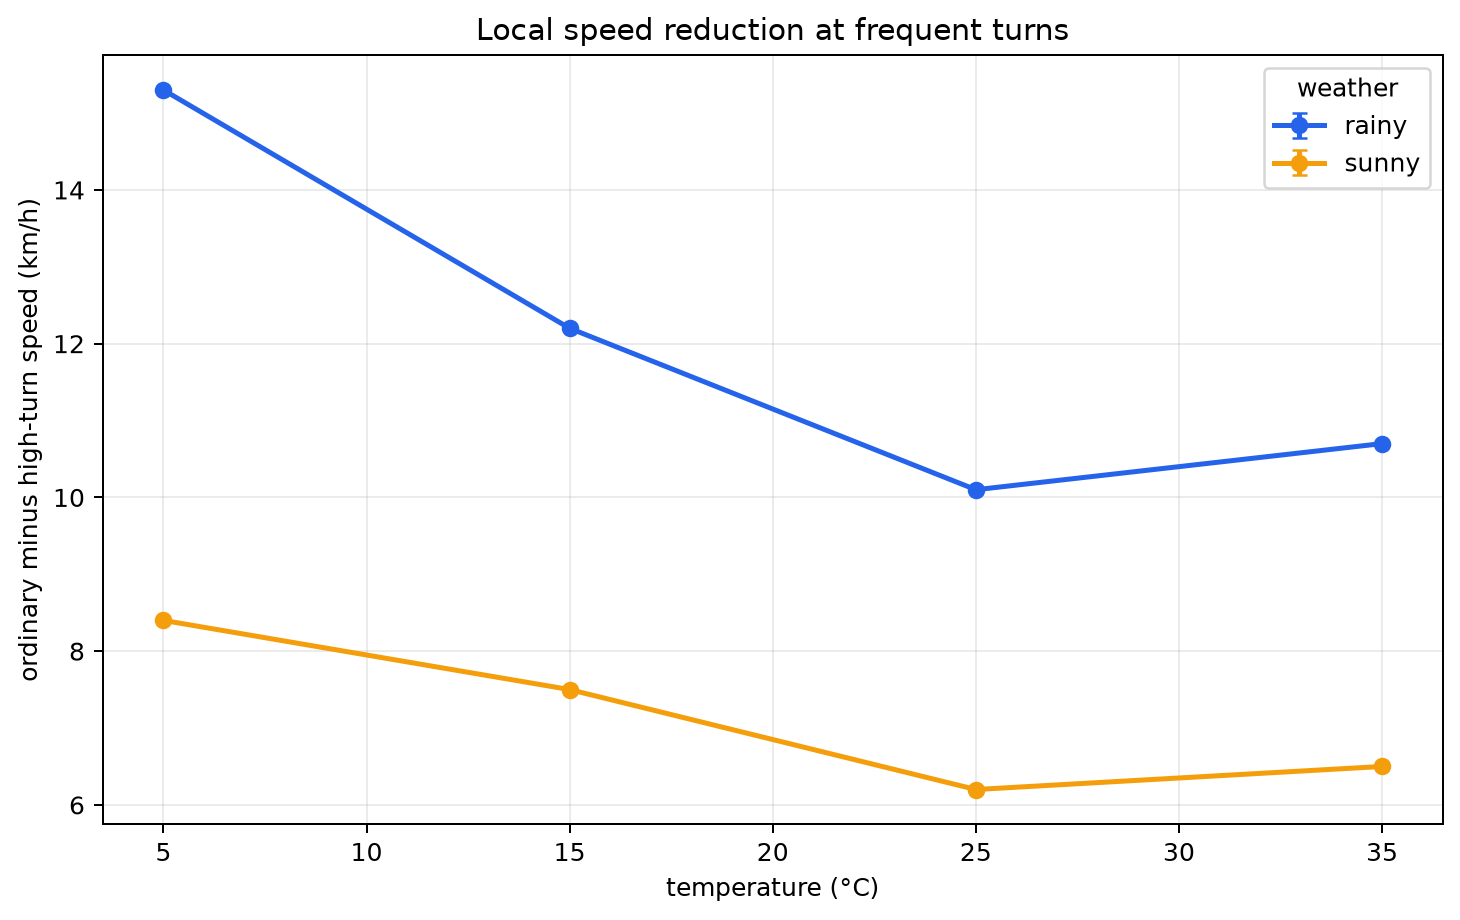

In [ ]:
q=user_df[user_df.travel_mode.eq('car')].copy()
per_trip=q.groupby(['trajectory_id','weather','temperature_c','is_high_turn_segment']).speed_kmh.mean().unstack('is_high_turn_segment');per_trip['observed_reduction_kmh']=per_trip[False]-per_trip[True]
g=per_trip.groupby(['weather','temperature_c']).observed_reduction_kmh.agg(['mean','std','count']);print(g.round(2))
fig,ax=plt.subplots(figsize=(8,5),constrained_layout=True)
for weather,color in [('rainy','#2563eb'),('sunny','#f59e0b')]:
    z=g.xs(weather,level='weather');ax.errorbar(z.index,z['mean'],yerr=z['std'],marker='o',capsize=3,linewidth=2,label=weather,color=color)
ax.set(title='Local speed reduction at frequent turns',xlabel='temperature (°C)',ylabel='ordinary minus high-turn speed (km/h)');ax.legend(title='weather');ax.grid(alpha=.25);plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex17_insight_2",
  "insight": "During adverse weather, trajectories with frequent turns experience larger local speed reductions compared to trajectories in mild weather conditions.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Environmental-Condition Travel Behavior: Insight 2",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "How does the local speed reduction at frequent turns vary between rainy and mild weather across temperatures?",
  "actionable_insight": "Derive each trajectory's ordinary-section minus high-turn-section speed from point observations, then aggregate by weather and temperature.",
  "code": "q=user_df[user_df.travel_mode.eq('car')].copy()\nper_trip=q.groupby(['trajectory_id','weather','temperature_c','is_high_turn_segment']).speed_kmh.mean().unstack('is_high_turn_segment');per_trip['observed_reduction_kmh']=per_trip[False]-per_trip[True]\ng=per_trip.groupby(['weather','temperature_c']).observed_reduction_kmh.agg(['mean','std','count']);print(g.round(2))\nfig,ax=plt.subplots(figsize=(8,5),constrained_layout=True)\nfor weather,color in [('rainy','#2563eb'),('sunny','#f59e0b')]:\n    z=g.xs(weather,level='weather');ax.errorbar(z.index,z['mean'],yerr=z['std'],marker='o',capsize=3,linewidth=2,label=weather,color=color)\nax.set(title='Local speed reduction at frequent turns',xlabel='temperature (°C)',ylabel='ordinary minus high-turn speed (km/h)');ax.legend(title='weather');ax.grid(alpha=.25);plt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "matched_road_position",
    "weather",
    "temperature",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "transport_mode"
  ]
}

### **Question 3**: Does poor-weather car dominance expand mobility, or is it concentrated in shorter trajectories?

#### Analysis action

Compare mode shares and car-distance distributions, then directly compare the aggregate geographic footprints covered by all poor- and mild-weather car trajectories.

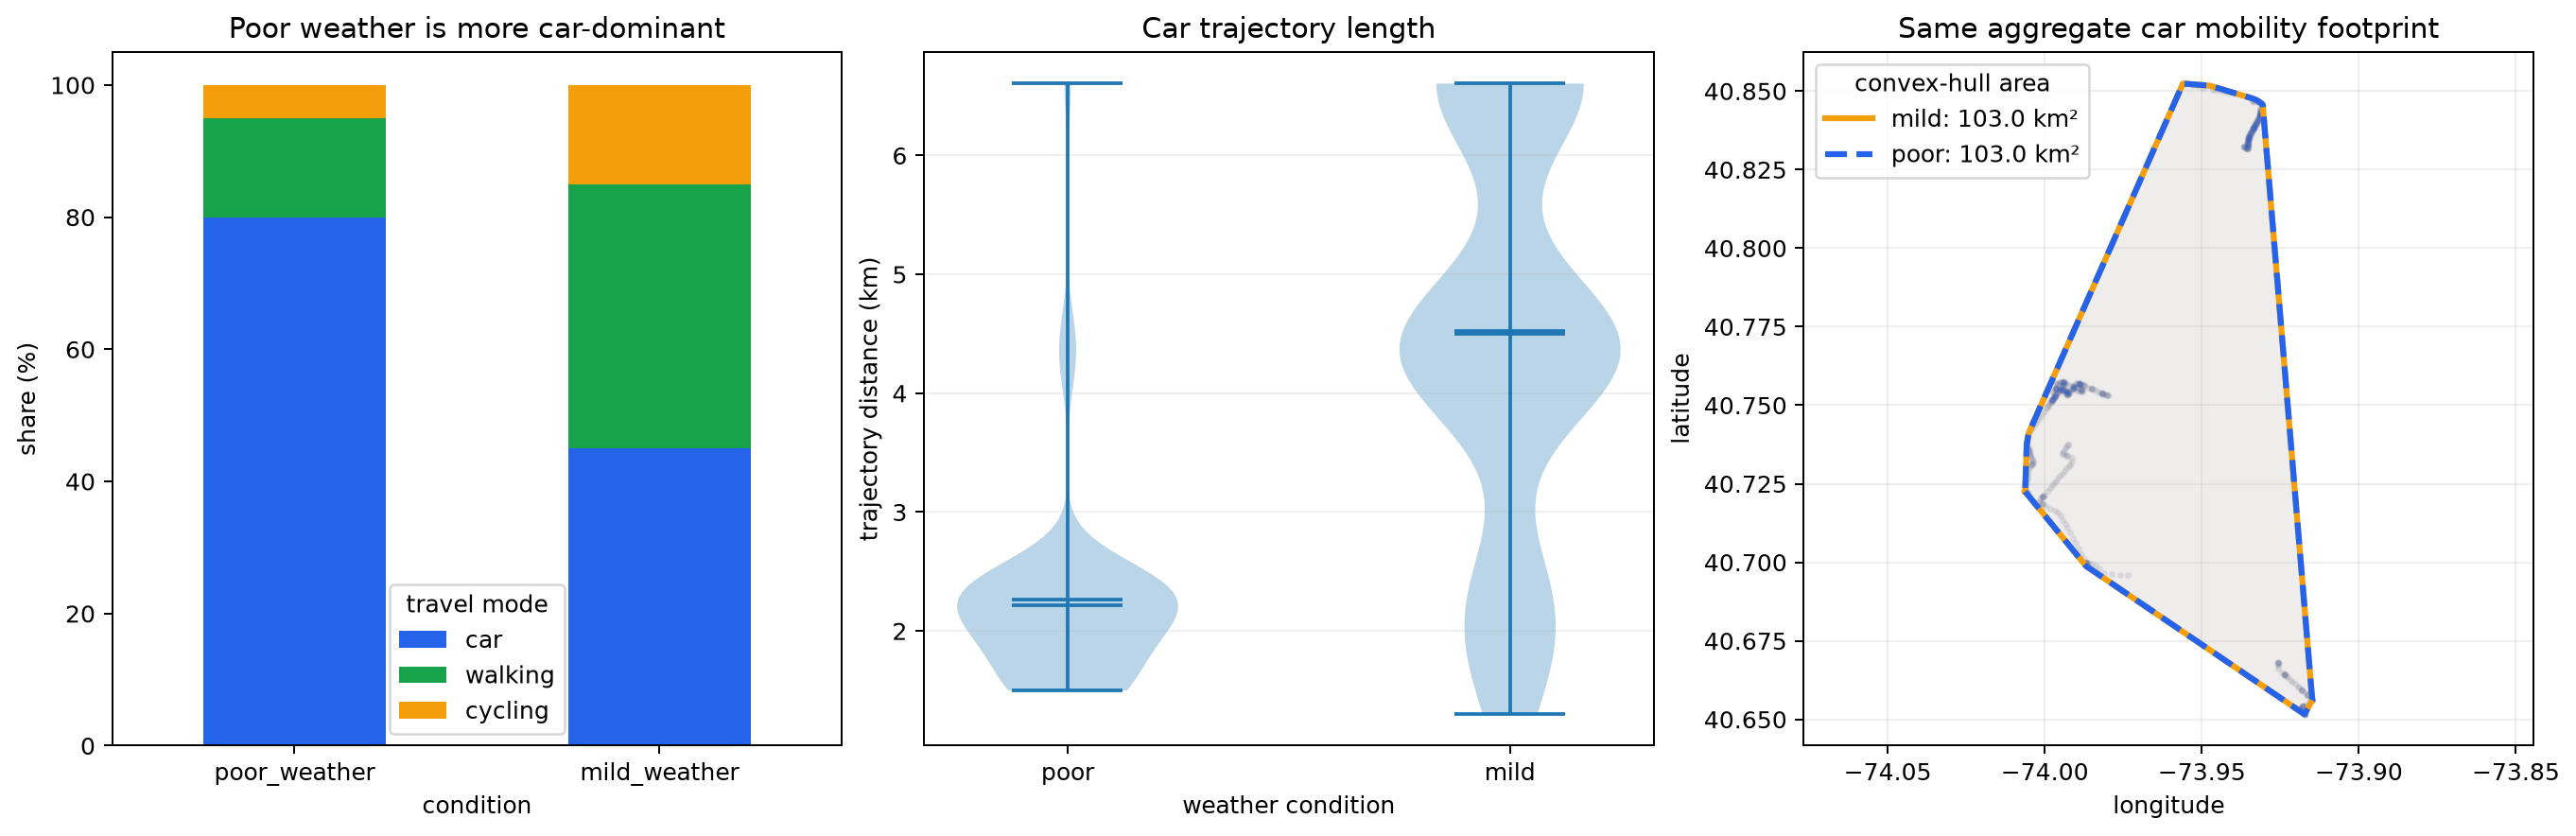

In [ ]:
order=['poor_weather','mild_weather'];tab=(pd.crosstab(df.weather_group,df.travel_mode,normalize='index')*100).reindex(order)[['car','walking','cycling']]
c=df[df.travel_mode.eq('car')];stats=c.groupby('weather_group').agg(trips=('trajectory_id','size'),minimum_distance=('trajectory_distance_km','min'),mean_distance=('trajectory_distance_km','mean')).reindex(order)
def convex_hull(points):
    pts=sorted(set(map(tuple,points)))
    def cross(o,a,b): return (a[0]-o[0])*(b[1]-o[1])-(a[1]-o[1])*(b[0]-o[0])
    lower=[]
    for p in pts:
        while len(lower)>=2 and cross(lower[-2],lower[-1],p)<=0: lower.pop()
        lower.append(p)
    upper=[]
    for p in reversed(pts):
        while len(upper)>=2 and cross(upper[-2],upper[-1],p)<=0: upper.pop()
        upper.append(p)
    return np.asarray(lower[:-1]+upper[:-1])
def aggregate_footprint(group):
    points=user_df[(user_df.travel_mode.eq('car')) & (user_df.condition_group.eq(group))][['matched_road_longitude','matched_road_latitude']].drop_duplicates().to_numpy()
    hull=convex_hull(points);lat0=np.deg2rad(hull[:,1].mean());xy=np.c_[hull[:,0]*111*np.cos(lat0),hull[:,1]*111]
    area=.5*abs(np.dot(xy[:,0],np.roll(xy[:,1],-1))-np.dot(xy[:,1],np.roll(xy[:,0],-1)))
    return points,hull,area
footprints={group:aggregate_footprint(group) for group in order}
print('Mode shares (%)');print(tab.round(1));print('Car trajectory distances');print(stats.round(2));print('Aggregate car footprint (convex-hull km²)');print(pd.Series({x:footprints[x][2] for x in order}).round(3))
fig,ax=plt.subplots(1,3,figsize=(15,4.8),constrained_layout=True);tab.plot.bar(stacked=True,ax=ax[0],color=['#2563eb','#16a34a','#f59e0b']);ax[0].set(title='Poor weather is more car-dominant',xlabel='condition',ylabel='share (%)');ax[0].tick_params(axis='x',rotation=0);ax[0].legend(title='travel mode')
distance=[c[c.weather_group.eq(x)].trajectory_distance_km for x in order]
ax[1].violinplot(distance,showmeans=True,showmedians=True);ax[1].set_xticks([1,2],['poor','mild']);ax[1].set(title='Car trajectory length',xlabel='weather condition',ylabel='trajectory distance (km)');ax[1].grid(axis='y',alpha=.2)
styles={'mild_weather':('#f59e0b','-'),'poor_weather':('#2563eb','--')}
for group in ['mild_weather','poor_weather']:
    points,hull,area=footprints[group];closed=np.vstack([hull,hull[0]]);color,style=styles[group]
    ax[2].scatter(points[:,0],points[:,1],s=4,color=color,alpha=.06)
    ax[2].fill(hull[:,0],hull[:,1],color=color,alpha=.07)
    ax[2].plot(closed[:,0],closed[:,1],style,color=color,linewidth=2.5,label=f"{group.replace('_weather','')}: {area:.1f} km²")
ax[2].set(title='Same aggregate car mobility footprint',xlabel='longitude',ylabel='latitude');ax[2].legend(title='convex-hull area');ax[2].set_aspect('equal',adjustable='datalim');ax[2].grid(alpha=.2);plt.show()
# Display the synchronized figure.
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex17_insight_3",
  "insight": "Although car travel becomes more dominant during poor weather, the car trajectories in such cases are concentrated in relatively shorter-distance movements and do not increase the overall spatial extent of mobility.",
  "plot": {
    "plot_type": "map_and_statistical_summary",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Environmental-Condition Travel Behavior: Insight 3",
    "description": "The map uses map-matched WorldTrace road geometry; the question-specific panel is computed from the same final CSV tables."
  },
  "question": "Does poor-weather car dominance expand mobility, or is it concentrated in shorter trajectories?",
  "actionable_insight": "Compare mode shares and car-distance distributions, then directly compare the aggregate geographic footprints covered by all poor- and mild-weather car trajectories.",
  "code": "order=['poor_weather','mild_weather'];tab=(pd.crosstab(df.weather_group,df.travel_mode,normalize='index')*100).reindex(order)[['car','walking','cycling']]\nc=df[df.travel_mode.eq('car')];stats=c.groupby('weather_group').agg(trips=('trajectory_id','size'),minimum_distance=('trajectory_distance_km','min'),mean_distance=('trajectory_distance_km','mean')).reindex(order)\ndef convex_hull(points):\n    pts=sorted(set(map(tuple,points)))\n    def cross(o,a,b): return (a[0]-o[0])*(b[1]-o[1])-(a[1]-o[1])*(b[0]-o[0])\n    lower=[]\n    for p in pts:\n        while len(lower)>=2 and cross(lower[-2],lower[-1],p)<=0: lower.pop()\n        lower.append(p)\n    upper=[]\n    for p in reversed(pts):\n        while len(upper)>=2 and cross(upper[-2],upper[-1],p)<=0: upper.pop()\n        upper.append(p)\n    return np.asarray(lower[:-1]+upper[:-1])\ndef aggregate_footprint(group):\n    points=user_df[(user_df.travel_mode.eq('car')) & (user_df.condition_group.eq(group))][['matched_road_longitude','matched_road_latitude']].drop_duplicates().to_numpy()\n    hull=convex_hull(points);lat0=np.deg2rad(hull[:,1].mean());xy=np.c_[hull[:,0]*111*np.cos(lat0),hull[:,1]*111]\n    area=.5*abs(np.dot(xy[:,0],np.roll(xy[:,1],-1))-np.dot(xy[:,1],np.roll(xy[:,0],-1)))\n    return points,hull,area\nfootprints={group:aggregate_footprint(group) for group in order}\nprint('Mode shares (%)');print(tab.round(1));print('Car trajectory distances');print(stats.round(2));print('Aggregate car footprint (convex-hull km²)');print(pd.Series({x:footprints[x][2] for x in order}).round(3))\nfig,ax=plt.subplots(1,3,figsize=(15,4.8),constrained_layout=True);tab.plot.bar(stacked=True,ax=ax[0],color=['#2563eb','#16a34a','#f59e0b']);ax[0].set(title='Poor weather is more car-dominant',xlabel='condition',ylabel='share (%)');ax[0].tick_params(axis='x',rotation=0);ax[0].legend(title='travel mode')\ndistance=[c[c.weather_group.eq(x)].trajectory_distance_km for x in order]\nax[1].violinplot(distance,showmeans=True,showmedians=True);ax[1].set_xticks([1,2],['poor','mild']);ax[1].set(title='Car trajectory length',xlabel='weather condition',ylabel='trajectory distance (km)');ax[1].grid(axis='y',alpha=.2)\nstyles={'mild_weather':('#f59e0b','-'),'poor_weather':('#2563eb','--')}\nfor group in ['mild_weather','poor_weather']:\n    points,hull,area=footprints[group];closed=np.vstack([hull,hull[0]]);color,style=styles[group]\n    ax[2].scatter(points[:,0],points[:,1],s=4,color=color,alpha=.06)\n    ax[2].fill(hull[:,0],hull[:,1],color=color,alpha=.07)\n    ax[2].plot(closed[:,0],closed[:,1],style,color=color,linewidth=2.5,label=f\"{group.replace('_weather','')}: {area:.1f} km²\")\nax[2].set(title='Same aggregate car mobility footprint',xlabel='longitude',ylabel='latitude');ax[2].legend(title='convex-hull area');ax[2].set_aspect('equal',adjustable='datalim');ax[2].grid(alpha=.2);plt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "transport_mode",
    "weather",
    "matched_road_position",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 17)

Rainy trajectories exhibit lower average speeds than dry-weather trajectories, but the reduction is substantially stronger for longer car trips than for short car trips. During adverse weather, trajectories with frequent turns experience larger local speed reductions compared to trajectories in mild weather conditions. Although car travel becomes more dominant during poor weather, the car trajectories in such cases are concentrated in relatively shorter-distance movements and do not increase the overall spatial extent of mobility.